# ECCO Procurement PostgreSQL Data Quality Assessment

This notebook is the primary, reproducible data-quality and descriptive-EDA report for the live `ecco_procurement` PostgreSQL database. Every reported number is computed when the notebook runs; no statistics are hardcoded.

The assessment is descriptive only. It documents structure, completeness, uniqueness, referential integrity, distributions, time coverage, and known limitations. It does not make business recommendations, pricing decisions, forecasts, or causal claims.

**Execution note:** Run all cells from the project root or use the root-discovery code below. The notebook reads credentials from `.env` and never displays the password.


## Table readability aliases (code only)

These readable names are used in display labels, summaries, and notebook headings only. The original PostgreSQL table names remain unchanged in all SQL and database access.

| Database table | Readable code name |
|---|---|
| `dim_purchasing_org` | `DIM_PURCHASING_ORG_NAME` |
| `dim_plant` | `DIM_FACTORY_INFO` |
| `dim_vendor` | `DIM_SUPPLIER-VENDOR_INFO` |
| `dim_material` | `DIM_MATERIAL_INFO` |
| `dim_commodity` | `DIM_COMMODITY_INFO` |
| `bridge_vendor_material` | `BRIDGE_VENDOR_MATERIAL` |
| `bridge_material_commodity` | `BRIDGE_MATERIAL_COMMODITY` |
| `fact_procurement_monthly` | `FACT_PROCUREMENT_MONTHLY_SPEND` |
| `fact_vendor_performance_quarterly` | `FACT_VENDOR_PERFORMANCE_QUARTERLY` |
| `fact_commodity_monthly` | `FACT_COMMODITY_MONTHLY_PRICE` |
| `fact_fx_monthly` | `FACT_FX_MONTHLY_EXCHANGE_RATE` |


In [1]:
# 2. Imports, reproducibility, and safe project-root discovery
import os
import sys
import json
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from IPython.display import display, Markdown
from sqlalchemy import URL, create_engine, inspect, text
from sqlalchemy.exc import SQLAlchemyError

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 110
warnings.filterwarnings('default')

def find_project_root(start=None):
    start_path = Path(start or Path.cwd()).resolve()
    candidates = [start_path, *start_path.parents]
    for candidate in candidates:
        if (candidate / '.env').exists() and (candidate / 'requirements.txt').exists():
            return candidate
    raise FileNotFoundError('Could not find project root containing .env and requirements.txt.')

PROJECT_ROOT = find_project_root()
ENV_FILE = PROJECT_ROOT / '.env'
load_dotenv(dotenv_path=ENV_FILE)

print('Project root:', PROJECT_ROOT)
print('Python:', sys.version.split()[0])
print('Pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('Matplotlib:', plt.matplotlib.__version__)
print('Seaborn:', sns.__version__)

TABLE_READABLE_NAMES = {
    "dim_purchasing_org": "DIM_PURCHASING_ORG_NAME",
    "dim_plant": "DIM_FACTORY_INFO",
    "dim_vendor": "DIM_SUPPLIER-VENDOR_INFO",
    "dim_material": "DIM_MATERIAL_INFO",
    "dim_commodity": "DIM_COMMODITY_INFO",
    "bridge_vendor_material": "BRIDGE_VENDOR_MATERIAL",
    "bridge_material_commodity": "BRIDGE_MATERIAL_COMMODITY",
    "fact_procurement_monthly": "FACT_PROCUREMENT_MONTHLY_SPEND",
    "fact_vendor_performance_quarterly": "FACT_VENDOR_PERFORMANCE_QUARTERLY",
    "fact_commodity_monthly": "FACT_COMMODITY_MONTHLY_PRICE",
    "fact_fx_monthly": "FACT_FX_MONTHLY_EXCHANGE_RATE",
}

def readable_table_name(table_name):
    return TABLE_READABLE_NAMES.get(str(table_name), str(table_name))

print("Table readability aliases loaded.")


Project root: C:\Users\Rohit Halder\projects\INDIUM_INTERNSHIP
Python: 3.14.4
Pandas: 3.1.0
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
Table readability aliases loaded.


In [2]:
# 3. Connect to PostgreSQL without exposing credentials
required = ['PGDATABASE', 'PGUSER', 'PGPASSWORD']
missing = [name for name in required if not os.getenv(name)]
if missing:
    raise ValueError(f'Missing environment variables: {", ".join(missing)}')

DB_HOST = os.getenv('PGHOST', 'localhost')
DB_PORT = int(os.getenv('PGPORT', '5432'))
DB_NAME = os.environ['PGDATABASE']
DB_USER = os.environ['PGUSER']
DB_PASSWORD = os.environ['PGPASSWORD']

database_url = URL.create(
    drivername='postgresql+psycopg2',
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME,
)
engine = create_engine(database_url, pool_pre_ping=True)

try:
    with engine.connect() as conn:
        db_name, db_user, server_version = conn.execute(text('''
            SELECT current_database(), current_user, version()
        ''')).one()
except SQLAlchemyError as exc:
    engine.dispose()
    raise RuntimeError('Database connection failed. Check PostgreSQL, .env, and permissions.') from exc

print('Database connection successful.')
print('Database:', db_name)
print('User:', db_user)
print('PostgreSQL:', server_version.split(',')[0])
print('Execution UTC:', datetime.now(timezone.utc).isoformat())


Database connection successful.
Database: ecco_procurement
User: postgres
PostgreSQL: PostgreSQL 18.4 on x86_64-windows
Execution UTC: 2026-10-29T20:06:19.868172+00:00


## 2. Database and table inventory

The next cells discover user-defined tables and views through `information_schema` and SQLAlchemy inspection. Row counts are exact `COUNT(*)` results. Objects that cannot be inspected or counted are retained in the inventory with an error status.

In [3]:
# 4. Metadata helpers and dynamic object discovery
inspector = inspect(engine)
SYSTEM_SCHEMAS = {'pg_catalog', 'information_schema', 'pg_toast'}

schemas = [s for s in inspector.get_schema_names() if s not in SYSTEM_SCHEMAS]
objects = []
for schema in schemas:
    try:
        for table_name in inspector.get_table_names(schema=schema):
            objects.append({'schema_name': schema, 'object_name': table_name, 'object_type': 'table'})
        for view_name in inspector.get_view_names(schema=schema):
            objects.append({'schema_name': schema, 'object_name': view_name, 'object_type': 'view'})
    except Exception as exc:
        objects.append({'schema_name': schema, 'object_name': None, 'object_type': 'schema_error', 'error': str(exc)})

objects_df = pd.DataFrame(objects)
if objects_df.empty:
    raise RuntimeError('No user-defined tables or views were discovered.')

def qident(value):
    return '"' + str(value).replace('"', '""') + '"'

def object_ref(schema, name):
    return f'{qident(schema)}.{qident(name)}'

def fetch_table(schema, name):
    return pd.read_sql_query(f'SELECT * FROM {object_ref(schema, name)}', engine)

def exact_count(schema, name):
    return int(pd.read_sql_query(f'SELECT COUNT(*) AS row_count FROM {object_ref(schema, name)}', engine).iloc[0, 0])

objects_df


,schema_name,object_name,object_type
0,public,bridge_material_commodity,table
1,public,bridge_vendor_material,table
2,public,dim_commodity,table
3,public,dim_material,table
4,public,fact_procurement_monthly,table
5,public,fact_fx_monthly,table
6,public,data_quality_issue_register,table
7,public,fact_vendor_performance_quarterly,table
8,public,fact_commodity_monthly,table
9,public,dim_vendor,table


### table-column overview
This code performs a table-wise inventory of all discovered database tables and views, while also conducting column-wise missing-value checks and column data-type inspection.

For each object, it retrieves database metadata, loads its data, counts its rows and columns, calculates how many columns belong to each recognized data-type category, and records primary-key and foreign-key information. It also checks each column for missing values and calculates the missing percentage, storing the results for a separate detailed report.

The final inventory provides an overview of the database structure, while the missing-value report provides a more granular view of data completeness.

It is an initial structural profiling and missing-value assessment, not a complete data-quality validation. Duplicate detection, identifier uniqueness, referential integrity validation, outlier detection, and procurement-specific business-rule checks would need separate analysis steps.

In [4]:

# 5. Build the table inventory from live metadata
inventory_rows = []
access_errors = []
# missing_value_reports = []

for row in objects_df.to_dict('records'):
    schema, name, obj_type = (
        row['schema_name'],
        row['object_name'],
        row['object_type']
    )

    if obj_type == 'schema_error':
        access_errors.append(row)
        continue

    try:
        columns = inspector.get_columns(name, schema=schema)

        pk = (
            inspector.get_pk_constraint(name, schema=schema)
            .get('constrained_columns') or []
        )

        fks = inspector.get_foreign_keys(name, schema=schema)

        # Load the current table/view into a DataFrame
        df = fetch_table(schema, name)

        # # Check missing values in every column
        # missing_count = df.isna().sum()

        # # Calculate missing-value percentage for every column
        # missing_percentage = (
        #     (missing_count / len(df) * 100).round(2)
        #     if len(df) > 0
        #     else pd.Series(0.0, index=df.columns)
        # )

        # # Keep only columns that contain missing values
        # missing_report = pd.DataFrame({
        #     'schema_name': schema,
        #     'object_name': name,
        #     'readable_table_name': readable_table_name(name),
        #     'column_name': missing_count.index,
        #     'missing_count': missing_count.values,
        #     'missing_percentage': missing_percentage.values
        # })

        # missing_report = missing_report[
        #     missing_report['missing_count'] > 0
        # ]

        # # Store missing-value results for later review
        # if not missing_report.empty:
        #     missing_value_reports.append(missing_report)

        # Count column data types
        numeric_count = int(sum(
            pd.api.types.is_numeric_dtype(dtype)
            for dtype in df.dtypes
        ))

        date_count = int(sum(
            pd.api.types.is_datetime64_any_dtype(dtype)
            for dtype in df.dtypes
        ))

        text_count = int(sum(
            pd.api.types.is_object_dtype(dtype)
            or pd.api.types.is_string_dtype(dtype)
            for dtype in df.dtypes
        ))

        bool_count = int(sum(
            pd.api.types.is_bool_dtype(dtype)
            for dtype in df.dtypes
        ))

        # Store table inventory information
        inventory_rows.append({
            'schema_name': schema,
            'object_name': name,
            'object_type': obj_type,
            'row_count': len(df),
            'column_count': len(columns),
            'numeric_columns': numeric_count,
            'Non-Numeric Columns': text_count,
            'date_time_columns': date_count,
            'boolean_columns': bool_count,
            'primary_key_columns': len(pk),
            'foreign_key_constraints': len(fks),
             'analysis_status': 'analyzed',
            # 'error': None,
        })

    except Exception as exc:
        access_errors.append({
            'schema_name': schema,
            'object_name': name,
            'object_type': obj_type,
            'error': str(exc)
        })

        inventory_rows.append({
            # 'schema_name': schema,
            'object_name': name,
            'object_type': obj_type,
            'row_count': np.nan,
            'column_count': np.nan,
            'numeric_columns': np.nan,
            'text_or_categorical_columns': np.nan,
            'date_time_columns': np.nan,
            'boolean_columns': np.nan,
            'primary_key_columns': np.nan,
            'foreign_key_constraints': np.nan,
             'analysis_status': 'failed',
            # 'error': str(exc)
        })


# Create and sort the final inventory
inventory_df = (
    pd.DataFrame(inventory_rows)
    .sort_values(['schema_name', 'object_name'])
    .reset_index(drop=True)
)

# Add readable table names without changing actual database names
inventory_df['readable_table_name'] = (
    inventory_df['object_name'].map(readable_table_name)
)

inventory_df.insert(
    2,
    'readable_table_name',
    inventory_df.pop('readable_table_name')
)

display(inventory_df)


# # Display missing-value details for all affected columns
# if missing_value_reports:
#     print('Missing Values Report:')

#     missing_values_df = pd.concat(
#         missing_value_reports,
#         ignore_index=True
#     )

#     display(missing_values_df)
# else:
#     print('No missing values found in the analyzed tables/views.')


# Display access or analysis errors
if access_errors:
    print('Access or discovery issues:')
    display(pd.DataFrame(access_errors))
else:
    print('No table access errors were recorded.')


,schema_name,object_name,readable_table_name,object_type,row_count,column_count,numeric_columns,Non-Numeric Columns,date_time_columns,boolean_columns,primary_key_columns,foreign_key_constraints,analysis_status
0,public,bridge_material_commodity,BRIDGE_MATERIAL_COMMODITY,table,3600,6,2,4,0,0,2,2,analyzed
1,public,bridge_vendor_material,BRIDGE_VENDOR_MATERIAL,table,2910,12,4,8,0,0,1,3,analyzed
2,public,data_quality_issue_register,data_quality_issue_register,table,2054,7,0,7,0,0,1,0,analyzed
3,public,dim_commodity,DIM_COMMODITY_INFO,table,13,5,0,5,0,0,1,0,analyzed
4,public,dim_material,DIM_MATERIAL_INFO,table,1200,9,0,9,0,0,1,0,analyzed
5,public,dim_plant,DIM_FACTORY_INFO,table,6,5,0,5,0,0,1,1,analyzed
6,public,dim_purchasing_org,DIM_PURCHASING_ORG_NAME,table,2,2,0,2,0,0,1,0,analyzed
7,public,dim_vendor,DIM_SUPPLIER-VENDOR_INFO,table,95,8,1,7,0,0,1,0,analyzed
8,public,fact_commodity_monthly,FACT_COMMODITY_MONTHLY_PRICE,table,1053,7,1,6,0,0,2,1,analyzed
9,public,fact_fx_monthly,FACT_FX_MONTHLY_EXCHANGE_RATE,table,729,6,1,5,0,0,3,0,analyzed


No table access errors were recorded.


## 3. Table structure and schema documentation
code creates a Column Dictionary for every successfully analyzed table or view in your ECCO Procurement database. It collects metadata about each column, including its data type, constraints, missing values, distinct values, and example values

## unique_count

In [5]:
# 6. Column-wise distinct count for each analyzed table/view

for row in inventory_df[
    inventory_df['analysis_status'] == 'analyzed'
].to_dict('records'):

    schema = row['schema_name']
    name = row['object_name']

    # Load the table data
    df = fetch_table(schema, name)

    # Build a compact column dictionary
    column_dictionary_df = pd.DataFrame({
        'table_name': name,
        'column_name': df.columns,
        'distinct_count': [
            df[col].nunique(dropna=True)
            for col in df.columns
        ]
    })

    # Display each table separately
    print(f"Table: {name}")
    display(column_dictionary_df[['table_name', 'column_name', 'distinct_count']])

Table: bridge_material_commodity


,table_name,column_name,distinct_count
0,bridge_material_commodity,material_id,1200
1,bridge_material_commodity,commodity_id,12
2,bridge_material_commodity,exposure_weight,5
3,bridge_material_commodity,lag_months,4
4,bridge_material_commodity,mapping_confidence,3
5,bridge_material_commodity,valid_from,1


Table: bridge_vendor_material


,table_name,column_name,distinct_count
0,bridge_vendor_material,vendor_material_id,2910
1,bridge_vendor_material,material_id,1200
2,bridge_vendor_material,vendor_id,95
3,bridge_vendor_material,plant_id,6
4,bridge_vendor_material,contract_id,397
5,bridge_vendor_material,approved_from,15
6,bridge_vendor_material,approved_to,1
7,bridge_vendor_material,contract_currency,8
8,bridge_vendor_material,quoted_unit_price,196
9,bridge_vendor_material,lead_time_days,65


Table: data_quality_issue_register


,table_name,column_name,distinct_count
0,data_quality_issue_register,issue_id,2054
1,data_quality_issue_register,issue_code,11
2,data_quality_issue_register,table_name,1
3,data_quality_issue_register,record_id,2054
4,data_quality_issue_register,business_key,2051
5,data_quality_issue_register,description,11
6,data_quality_issue_register,recommended_handling,11


... (14 outputs left out)

Table: fact_procurement_monthly


,table_name,column_name,distinct_count
0,fact_procurement_monthly,procurement_id,174638
1,fact_procurement_monthly,purch_org_id,2
2,fact_procurement_monthly,material_7,200
3,fact_procurement_monthly,material_id,1200
4,fact_procurement_monthly,vendor_id,96
5,fact_procurement_monthly,vendor_material_id,2910
6,fact_procurement_monthly,material_description,1200
7,fact_procurement_monthly,plant_id,6
8,fact_procurement_monthly,material_group_id,12
9,fact_procurement_monthly,month,81


Table: fact_vendor_performance_quarterly


,table_name,column_name,distinct_count
0,fact_vendor_performance_quarterly,performance_id,78570
1,fact_vendor_performance_quarterly,vendor_id,95
2,fact_vendor_performance_quarterly,plant_id,6
3,fact_vendor_performance_quarterly,quarter_start,27
4,fact_vendor_performance_quarterly,quarter_end,27
5,fact_vendor_performance_quarterly,delivery_lines,86
6,fact_vendor_performance_quarterly,on_time_delivery_pct,360
7,fact_vendor_performance_quarterly,defect_rate_pct,554
8,fact_vendor_performance_quarterly,avg_actual_lead_days,91
9,fact_vendor_performance_quarterly,price_variance_pct,3030


## Missing value count

In [6]:
# Full missing-value report for every table and column
# where missing_count > 0

missing_value_reports = []

for row in objects_df.to_dict("records"):
    schema = row["schema_name"]
    name = row["object_name"]
    obj_type = row["object_type"]

    if obj_type == "schema_error":
        continue

    try:
        df = fetch_table(schema, name)
    except Exception as exc:
        print(f"Error fetching table {schema}.{name}: {exc}")
        continue

    # Count missing values in every column
    missing_count = df.isna().sum()

    # Calculate missing percentages safely
    if len(df) > 0:
        missing_percentage = (
            missing_count.div(len(df)).mul(100).round(2)
        )
    else:
        missing_percentage = pd.Series(
            0.0,
            index=df.columns,
            dtype="float64",
        )

    # Build the report for the current table
    missing_report = pd.DataFrame({
        "schema_name": schema,
        "object_name": name,
        "readable_table_name": readable_table_name(name),
        "column_name": missing_count.index,
        "missing_count": missing_count.values,
        "missing_percentage": missing_percentage.values,
    })

    # Keep only columns with missing values
    missing_report = missing_report[
        missing_report["missing_count"] > 0
    ].reset_index(drop=True)

    # Keep this table's results
    if not missing_report.empty:
        missing_value_reports.append(missing_report)

# Combine results from every table
if missing_value_reports:
    missing_values_df = pd.concat(
        missing_value_reports,
        ignore_index=True,
    )

    missing_values_df = missing_values_df.sort_values(
        by=[
            "schema_name",
            "object_name",
            "column_name",
        ]
    ).reset_index(drop=True)

    print("Full Missing Values Report")
    print(
        f"Tables with missing values: "
        f"{missing_values_df['object_name'].nunique()}"
    )
    print(
        f"Columns with missing values: "
        f"{len(missing_values_df)}"
    )

    display(missing_values_df)
else:
    print("No missing values found in the analyzed tables or views.")

Full Missing Values Report
Tables with missing values: 4
Columns with missing values: 7


,schema_name,object_name,readable_table_name,column_name,missing_count,missing_percentage
0,public,bridge_vendor_material,BRIDGE_VENDOR_MATERIAL,approved_to,2739,94.12
1,public,dim_material,DIM_MATERIAL_INFO,active_to,1136,94.67
2,public,fact_commodity_monthly,FACT_COMMODITY_MONTHLY_PRICE,index_price,6,0.57
3,public,fact_procurement_monthly,FACT_PROCUREMENT_MONTHLY_SPEND,order_value_eur,193,0.11
4,public,fact_procurement_monthly,FACT_PROCUREMENT_MONTHLY_SPEND,order_value_local,193,0.11
5,public,fact_procurement_monthly,FACT_PROCUREMENT_MONTHLY_SPEND,po_qty,175,0.10
6,public,fact_procurement_monthly,FACT_PROCUREMENT_MONTHLY_SPEND,unit_price_local,66617,38.15


### ignore 


In [7]:
# # 6. Column dictionaries for every analyzed object
# column_rows = []
# for row in inventory_df[inventory_df['analysis_status'] == 'analyzed'].to_dict('records'):
#     schema, name = row['schema_name'], row['object_name']
#     df = fetch_table(schema, name)
#     columns = inspector.get_columns(name, schema=schema)
#     pk_cols = set(inspector.get_pk_constraint(name, schema=schema).get('constrained_columns') or [])
#     fk_rows = inspector.get_foreign_keys(name, schema=schema)
#     fk_by_col = {}
#     for fk in fk_rows:
#         for local, remote in zip(fk.get('constrained_columns') or [], fk.get('referred_columns') or []):
#             fk_by_col[local] = f"{fk.get('referred_schema')}.{fk.get('referred_table')}.{remote}"
#     unique_cols = set()
#     for constraint in inspector.get_unique_constraints(name, schema=schema):
#         unique_cols.update(constraint.get('column_names') or [])
#     comments = inspector.get_table_comment(name, schema=schema).get('text') or ''
#     for column in columns:
#         col = column['name']
#         series = df[col]
#         non_null = series.dropna()
#         # examples = [str(x) for x in non_null.head(3).tolist()]

#         column_rows.append({
#             # 'schema_name': schema, 
#             'table_name': name, 
#             'column_name': col,
#             # 'table_comment': comments,
#             # 'postgres_type': str(column['type']), 
#             # 'pandas_dtype': str(series.dtype),
#             # 'nullable': column.get('nullable'), 
#             # 'primary_key': col in pk_cols,
#             # 'foreign_key': col in fk_by_col, 
#             # 'references': fk_by_col.get(col),
#             # 'unique_constraint': col in unique_cols, 
#             # 'default': column.get('default'),
#             # 'null_count': int(series.isna().sum()), 
#             # 'null_percentage': (series.isna().sum() / len(series) * 100).round(2),
#             # 'non_null_count': int(series.notna().sum()),
#             'distinct_count': int(series.nunique(dropna=True)),
#             #   'example_values': examples,
#             # 'description': comments if comments else f'Inferred from column name and observed values; table comment unavailable.',
#         })
# column_dictionary_df = pd.DataFrame(column_rows)
# display(column_dictionary_df)


# # Display missing-value details for all affected columns
# if missing_value_reports:
#     print('Missing Values Report:')

#     missing_values_df = pd.concat(
#         missing_value_reports,
#         ignore_index=True
#     )

#     display(missing_values_df)
# else:
#     print('No missing values found in the analyzed tables/views.')


In [8]:
# # Display the complete bridge_vendor_material table

# BRIDGE_TABLE = "bridge_vendor_material"

# bridge_vendor_material_df = pd.read_sql_query(
#     f"""
#     SELECT *
#     FROM "{BRIDGE_TABLE}"
#     ORDER BY vendor_material_id
#     LIMIT 5;
#     """,
#     engine,
# )
# print(f"Rows: {len(bridge_vendor_material_df)}")
# print(f"Columns: {len(bridge_vendor_material_df.columns)}")

# display(bridge_vendor_material_df)

## 4. Table-level completeness, duplicates, and key quality

### a table-wise data quality summary for all successfully analyzed tables, measuring data completeness, missing values, and duplicate records. It also validates primary-key uniqueness and missing values, providing an overview of each table’s data quality and structural reliability.

In [9]:
# 7. Completeness and duplicate summary
quality_rows = []
for row in inventory_df[inventory_df['analysis_status'] == 'analyzed'].to_dict('records'):
    schema, name = row['schema_name'], row['object_name']
    df = fetch_table(schema, name)
    pk_cols = inspector.get_pk_constraint(name, schema=schema).get('constrained_columns') or []
    null_cells = int(df.isna().sum().sum())
    total_cells = int(df.shape[0] * df.shape[1])
    duplicate_full_rows = int(df.duplicated(keep=False).sum()) if len(df) else 0
    if pk_cols and len(df):
        duplicate_pk_rows = int(df.duplicated(subset=pk_cols, keep=False).sum())
        null_pk_rows = int(df[pk_cols].isna().any(axis=1).sum())
        pk_status = 'pass' if duplicate_pk_rows == 0 and null_pk_rows == 0 else 'fail'
    elif pk_cols:
        duplicate_pk_rows, null_pk_rows, pk_status = 0, 0, 'not_applicable_empty'
    else:
        duplicate_pk_rows, null_pk_rows, pk_status = np.nan, np.nan, 'not_defined'
    quality_rows.append({
        'schema_name': schema, 'table_name': name, 'row_count': len(df),
        'column_count': df.shape[1], 'null_cells': null_cells,
        'non_null_cells': int(total_cells - null_cells),
        'null_cell_pct': (null_cells / total_cells * 100) if total_cells else 0,
        'columns_with_nulls': int(df.isna().any().sum()),
        'completely_null_columns': int(df.isna().all().sum()),
        'columns_without_nulls': int((~df.isna().any()).sum()),
        'duplicate_full_rows': duplicate_full_rows,
        'duplicate_primary_key_rows': duplicate_pk_rows,
        'null_primary_key_rows': null_pk_rows,
        'primary_key_status': pk_status,
    })
quality_summary_df = pd.DataFrame(quality_rows)
quality_summary_df['readable_table_name'] = quality_summary_df['table_name'].map(readable_table_name)
quality_summary_df.insert(2, 'readable_table_name', quality_summary_df.pop('readable_table_name'))
display(quality_summary_df)


,schema_name,table_name,readable_table_name,row_count,column_count,null_cells,non_null_cells,null_cell_pct,columns_with_nulls,completely_null_columns,columns_without_nulls,duplicate_full_rows,duplicate_primary_key_rows,null_primary_key_rows,primary_key_status
0,public,bridge_material_commodity,BRIDGE_MATERIAL_COMMODITY,3600,6,0,21600,0.000000,0,0,6,0,0,0,pass
1,public,bridge_vendor_material,BRIDGE_VENDOR_MATERIAL,2910,12,2739,32181,7.843643,1,0,11,0,0,0,pass
2,public,data_quality_issue_register,data_quality_issue_register,2054,7,0,14378,0.000000,0,0,7,0,0,0,pass
3,public,dim_commodity,DIM_COMMODITY_INFO,13,5,0,65,0.000000,0,0,5,0,0,0,pass
4,public,dim_material,DIM_MATERIAL_INFO,1200,9,1136,9664,10.518519,1,0,8,0,0,0,pass
5,public,dim_plant,DIM_FACTORY_INFO,6,5,0,30,0.000000,0,0,5,0,0,0,pass
6,public,dim_purchasing_org,DIM_PURCHASING_ORG_NAME,2,2,0,4,0.000000,0,0,2,0,0,0,pass
7,public,dim_vendor,DIM_SUPPLIER-VENDOR_INFO,95,8,0,760,0.000000,0,0,8,0,0,0,pass
8,public,fact_commodity_monthly,FACT_COMMODITY_MONTHLY_PRICE,1053,7,6,7365,0.081400,1,0,6,0,0,0,pass
9,public,fact_fx_monthly,FACT_FX_MONTHLY_EXCHANGE_RATE,729,6,0,4374,0.000000,0,0,6,0,0,0,pass


### This cell validates foreign-key relationships across the database by checking whether child-table values match corresponding records in parent tables. It identifies potential referential integrity violations and reports the affected tables, columns, violation counts, and validation status (pass or fail).

In [10]:
# 8. Foreign-key validation from live data
fk_results = []
for row in inventory_df[inventory_df['analysis_status'] == 'analyzed'].to_dict('records'):
    schema, name = row['schema_name'], row['object_name']
    for fk in inspector.get_foreign_keys(name, schema=schema):
        local_cols = fk.get('constrained_columns') or []
        remote_schema = fk.get('referred_schema') or schema
        remote_table = fk['referred_table']
        remote_cols = fk.get('referred_columns') or []
        local_sql = ', '.join(qident(c) for c in local_cols)
        remote_sql = ', '.join(qident(c) for c in remote_cols)
        null_condition = ' OR '.join(f'child.{qident(c)} IS NULL' for c in local_cols)
        violation_sql = f'''SELECT COUNT(*) AS violation_count FROM {object_ref(schema, name)} child
            LEFT JOIN {object_ref(remote_schema, remote_table)} parent
            ON ({', '.join('child.' + qident(c) + ' = parent.' + qident(r) for c, r in zip(local_cols, remote_cols))})
            WHERE ({null_condition}) OR parent.{qident(remote_cols[0])} IS NULL'''
        violation_count = int(pd.read_sql_query(violation_sql, engine).iloc[0, 0])
        fk_results.append({'child_table': f'{schema}.{name}', 'child_columns': ', '.join(local_cols),
                           'parent_table': f'{remote_schema}.{remote_table}', 'parent_columns': ', '.join(remote_cols),
                           'violation_count': violation_count, 'status': 'pass' if violation_count == 0 else 'fail'})
fk_quality_df = pd.DataFrame(fk_results)
if not fk_quality_df.empty:
    fk_quality_df['child_table_label'] = fk_quality_df['child_table'].map(lambda x: x.split('.')[-1]).map(readable_table_name)
    fk_quality_df['parent_table_label'] = fk_quality_df['parent_table'].map(lambda x: x.split('.')[-1]).map(readable_table_name)
    fk_quality_df.insert(1, 'child_table_label', fk_quality_df.pop('child_table_label'))
    fk_quality_df.insert(3, 'parent_table_label', fk_quality_df.pop('parent_table_label'))
    display(fk_quality_df)
else:
    print('No foreign keys were discovered.')


,child_table,child_table_label,child_columns,parent_table_label,parent_table,parent_columns,violation_count,status
0,public.bridge_material_commodity,BRIDGE_MATERIAL_COMMODITY,commodity_id,DIM_COMMODITY_INFO,public.dim_commodity,commodity_id,0,pass
1,public.bridge_material_commodity,BRIDGE_MATERIAL_COMMODITY,material_id,DIM_MATERIAL_INFO,public.dim_material,material_id,0,pass
2,public.bridge_vendor_material,BRIDGE_VENDOR_MATERIAL,material_id,DIM_MATERIAL_INFO,public.dim_material,material_id,0,pass
3,public.bridge_vendor_material,BRIDGE_VENDOR_MATERIAL,plant_id,DIM_FACTORY_INFO,public.dim_plant,plant_id,0,pass
4,public.bridge_vendor_material,BRIDGE_VENDOR_MATERIAL,vendor_id,DIM_SUPPLIER-VENDOR_INFO,public.dim_vendor,vendor_id,0,pass
5,public.dim_plant,DIM_FACTORY_INFO,purch_org_id,DIM_PURCHASING_ORG_NAME,public.dim_purchasing_org,purch_org_id,0,pass
6,public.fact_commodity_monthly,FACT_COMMODITY_MONTHLY_PRICE,commodity_id,DIM_COMMODITY_INFO,public.dim_commodity,commodity_id,0,pass
7,public.fact_procurement_monthly,FACT_PROCUREMENT_MONTHLY_SPEND,material_id,DIM_MATERIAL_INFO,public.dim_material,material_id,0,pass
8,public.fact_procurement_monthly,FACT_PROCUREMENT_MONTHLY_SPEND,plant_id,DIM_FACTORY_INFO,public.dim_plant,plant_id,0,pass
9,public.fact_procurement_monthly,FACT_PROCUREMENT_MONTHLY_SPEND,purch_org_id,DIM_PURCHASING_ORG_NAME,public.dim_purchasing_org,purch_org_id,0,pass


## 5. Descriptive statistics and distributions

This cell performs column-wise statistical profiling across every successfully analyzed table in your ECCO Procurement database. It summarizes numeric data, identifies date coverage, and generates frequency tables for categorical or text columns.

In [11]:
# 9. Numeric summaries, date coverage, and categorical frequencies
numeric_summary_rows = []
date_summary_rows = []
categorical_frequencies = {}

for row in inventory_df[inventory_df["analysis_status"] == "analyzed"].to_dict("records"):
    schema, name = row["schema_name"], row["object_name"]
    df = fetch_table(schema, name)

    for col in df.columns:
        series = df[col]

        if pd.api.types.is_numeric_dtype(series):
            numeric_summary_rows.append({
                "schema_name": schema,
                "table_name": name,
                "column_name": col,
                "count": int(series.count()),
                "missing": int(series.isna().sum()),
                "mean": series.mean(),
                "std": series.std(),
                "min": series.min(),
                "q25": series.quantile(0.25),
                "median": series.median(),
                "q75": series.quantile(0.75),
                "max": series.max(),
                "distinct": int(series.nunique(dropna=True)),
            })

        column_name = str(col).lower()
        date_like_name = any(token in column_name for token in (
            "date", "month", "period", "timestamp", "time", "quarter"
        ))
        is_date_candidate = (
            pd.api.types.is_datetime64_any_dtype(series)
            or (
                (pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series))
                and date_like_name
            )
        )
        if is_date_candidate:
            converted = pd.to_datetime(series, errors="coerce", format="mixed")
            non_null_count = int(series.notna().sum())
            if not (non_null_count and converted.notna().sum() >= max(1, int(non_null_count * 0.8))):
                continue
            date_summary_rows.append({
                "schema_name": schema,
                "table_name": name,
                "column_name": col,
                "non_null_dates": int(converted.notna().sum()),
                "missing": int(series.isna().sum()),
                "min_date": converted.min(),
                "max_date": converted.max(),
                "distinct_dates": int(converted.nunique(dropna=True)),
            })

        if pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series):
            frequencies = (
                series.value_counts(dropna=False)
                .head(20)
                .rename_axis("value")
                .reset_index(name="count")
            )
            categorical_frequencies[f"{schema}.{name}.{col}"] = frequencies

numeric_summary_df = pd.DataFrame(numeric_summary_rows)
date_summary_df = pd.DataFrame(date_summary_rows)

# print(f"Categorical frequency tables generated: {len(categorical_frequencies)}")

# Display numeric and date summaries
display(numeric_summary_df)
display(date_summary_df)
print(f"Categorical frequency tables generated: {len(categorical_frequencies)}")


,schema_name,table_name,column_name,count,missing,mean,std,min,q25,median,q75,max,distinct
0,public,bridge_material_commodity,exposure_weight,3600,0,0.333333,0.277116,0.1000,0.1000,0.1800,0.72000,0.7500,5
1,public,bridge_material_commodity,lag_months,3600,0,1.416667,1.089876,0.0000,0.7500,1.0000,2.00000,3.0000,4
2,public,bridge_vendor_material,quoted_unit_price,2910,0,5.869316,3.061179,0.7000,3.1737,5.8300,8.49000,12.6431,196
3,public,bridge_vendor_material,lead_time_days,2910,0,46.962887,18.763971,15.0000,31.0000,47.0000,63.00000,79.0000,65
4,public,bridge_vendor_material,min_order_qty,2910,0,225.034364,175.074258,50.0000,62.5000,175.0000,437.50000,500.0000,4
5,public,bridge_vendor_material,allocation_target_pct,2910,0,38.738832,19.270572,0.0000,30.0000,30.0000,60.00000,60.0000,4
6,public,dim_vendor,payment_terms_days,95,0,55.894737,22.145300,30.0000,37.5000,45.0000,60.00000,90.0000,4
7,public,fact_commodity_monthly,index_price,1047,6,1359.914553,2827.378440,1.2422,13.5849,329.9886,989.14415,14105.9653,1047
8,public,fact_fx_monthly,units_per_eur,729,0,4425.187467,8515.765448,1.0000,4.6434,10.4029,99.87270,26873.5045,648
9,public,fact_procurement_monthly,order_value_local,174445,193,2866.607395,4493.524490,0.0000,0.0000,1311.6800,4069.09000,190513.9800,101766


,schema_name,table_name,column_name,non_null_dates,missing,min_date,max_date,distinct_dates
0,public,fact_commodity_monthly,month,1053,0,2020-01-01,2026-09-01,81
1,public,fact_fx_monthly,month,729,0,2020-01-01,2026-09-01,81
2,public,fact_procurement_monthly,month,174638,0,2020-01-01,2026-09-01,81
3,public,fact_vendor_performance_quarterly,quarter_start,78570,0,2020-01-01,2026-07-01,27
4,public,fact_vendor_performance_quarterly,quarter_end,78570,0,2020-03-01,2026-09-01,27


Categorical frequency tables generated: 78


In [12]:
# 10. Categorical frequency example index (all tables remain in categorical_frequencies)
frequency_index = []
for key, frequencies in categorical_frequencies.items():
    frequency_index.append({'object_column': key, 'displayed_values': len(frequencies), 'total_observed_rows': int(frequencies['count'].sum())})
frequency_index_df = pd.DataFrame(frequency_index).sort_values('object_column') if frequency_index else pd.DataFrame()
display(frequency_index_df)


,object_column,displayed_values,total_observed_rows
1,public.bridge_material_commodity.commodity_id,12,3600
2,public.bridge_material_commodity.mapping_confidence,3,3600
0,public.bridge_material_commodity.material_id,20,60
3,public.bridge_material_commodity.valid_from,1,3600
9,public.bridge_vendor_material.approved_from,15,2910
10,public.bridge_vendor_material.approved_to,2,2910
11,public.bridge_vendor_material.contract_currency,8,2910
8,public.bridge_vendor_material.contract_id,20,200
5,public.bridge_vendor_material.material_id,20,80
7,public.bridge_vendor_material.plant_id,6,2910


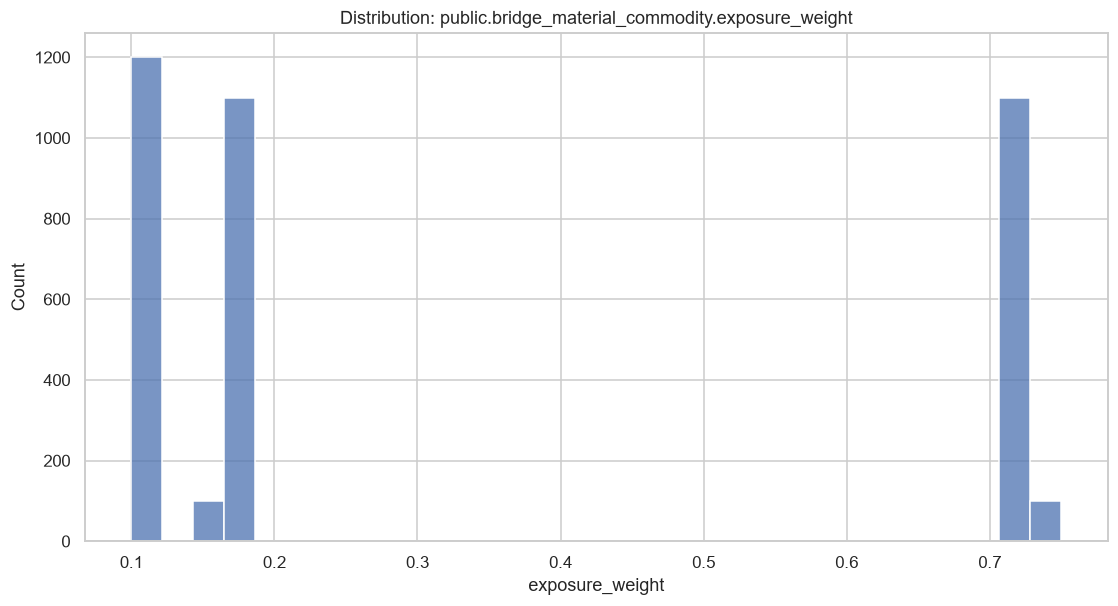

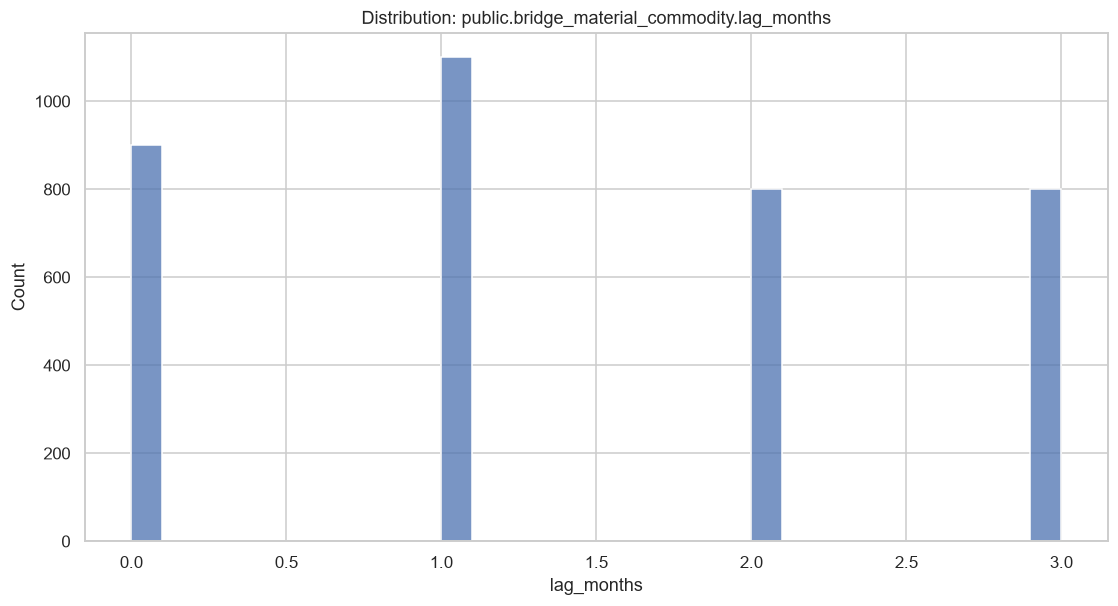

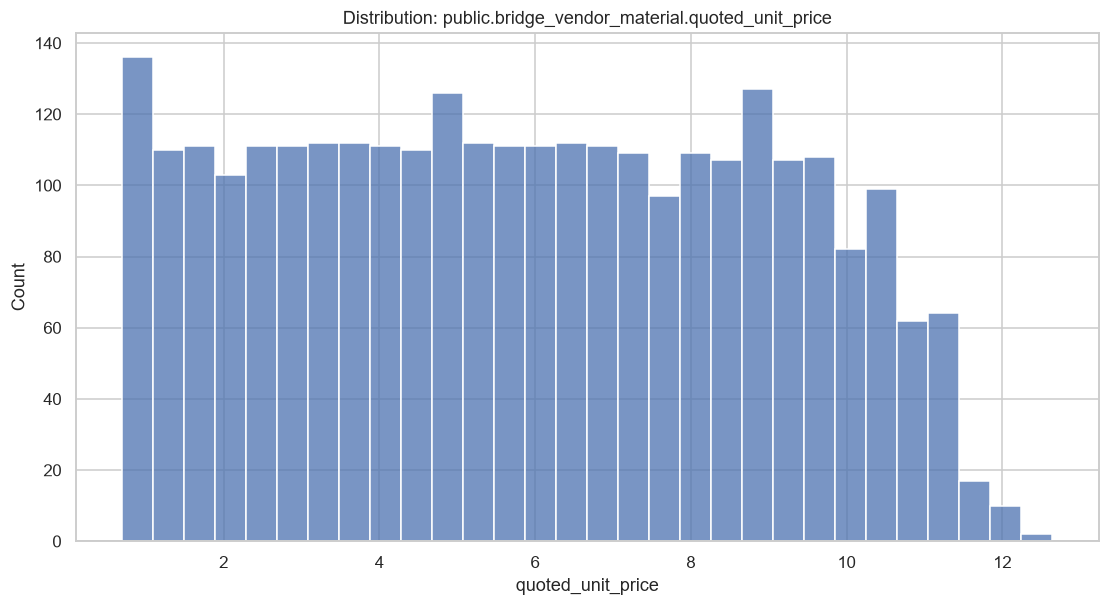

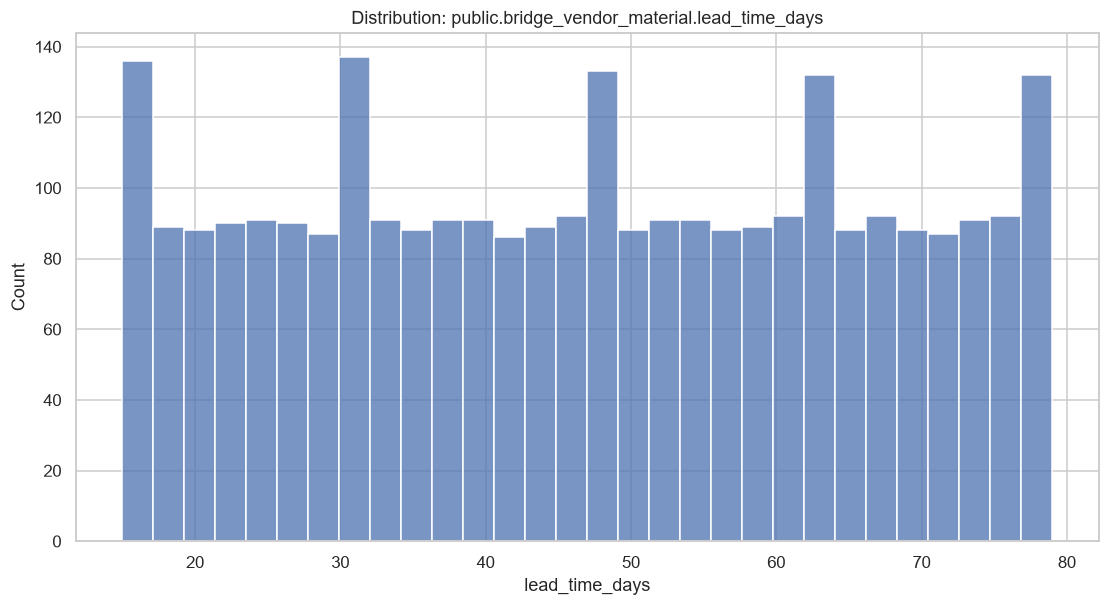

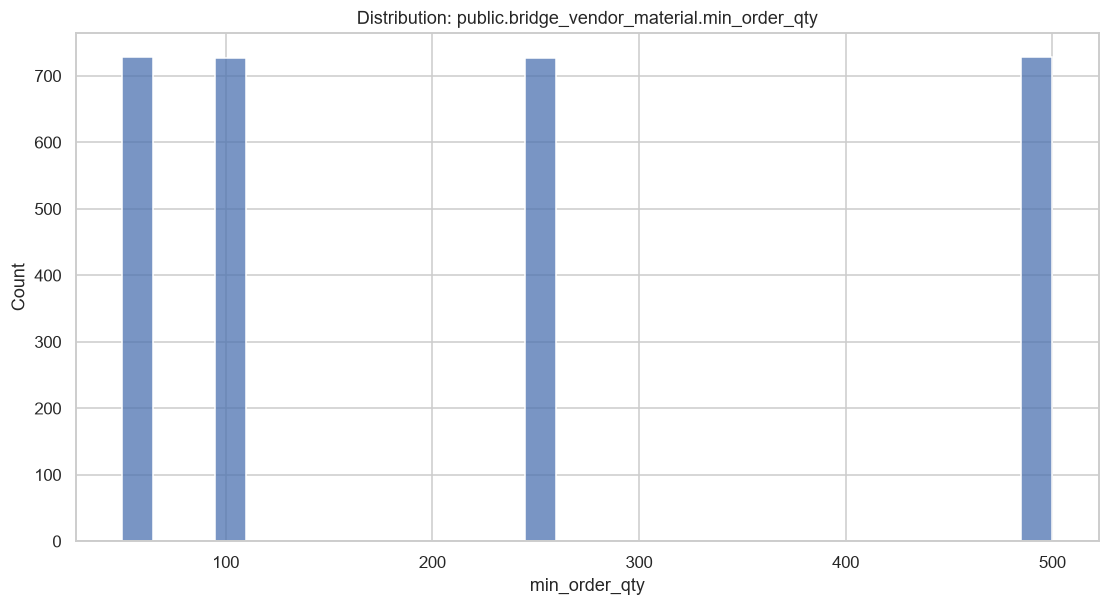

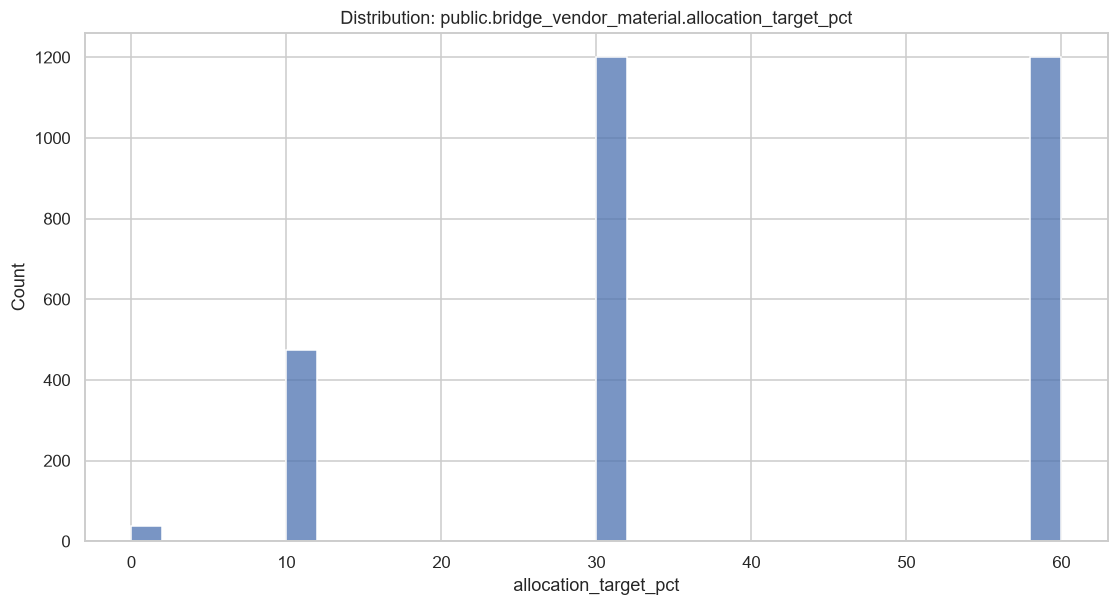

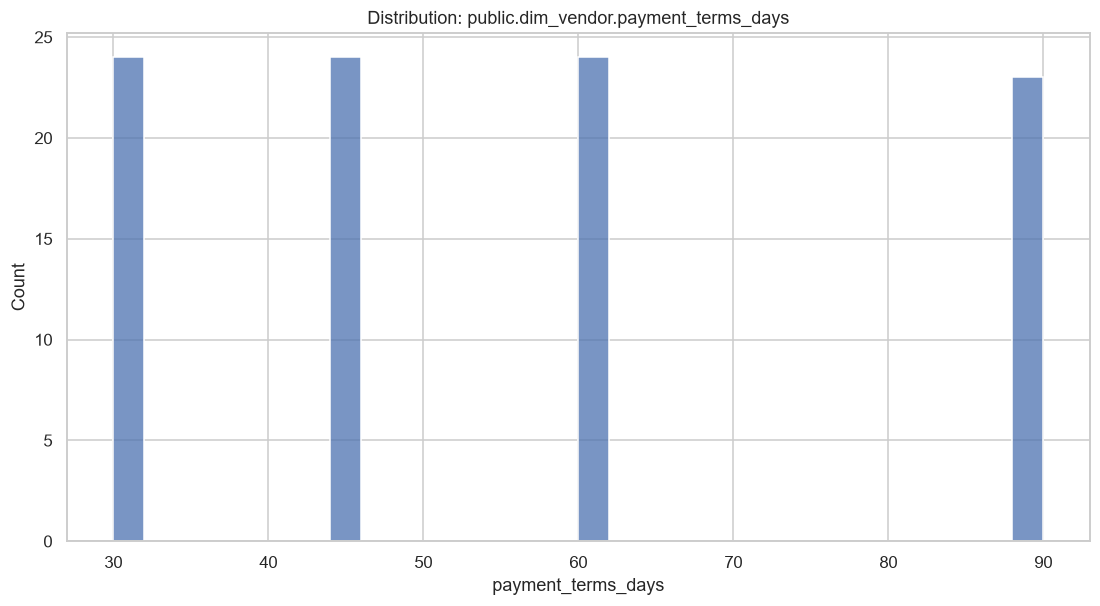

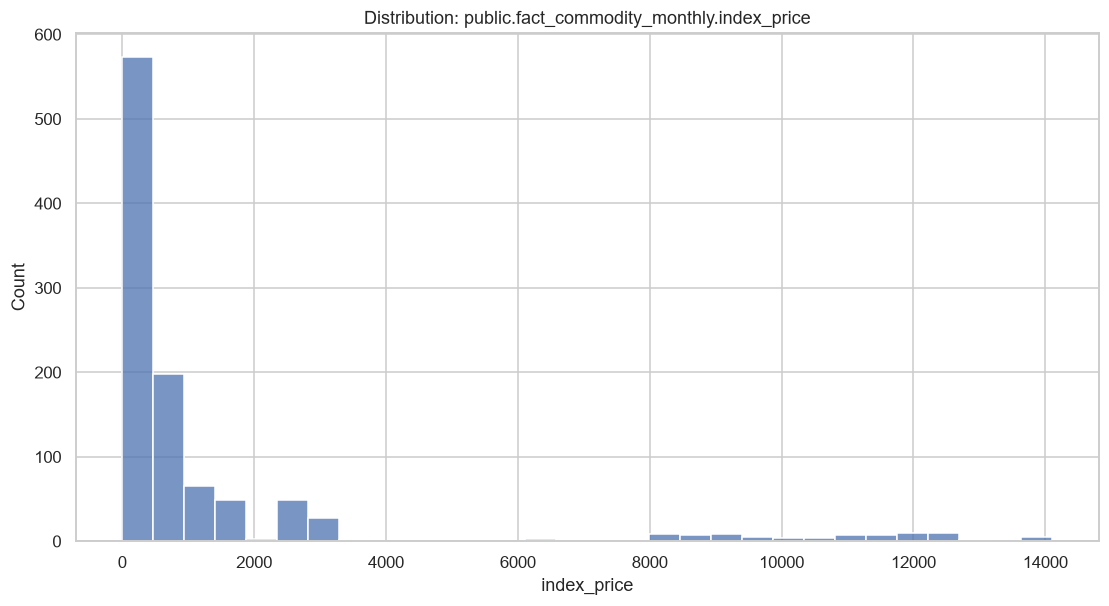

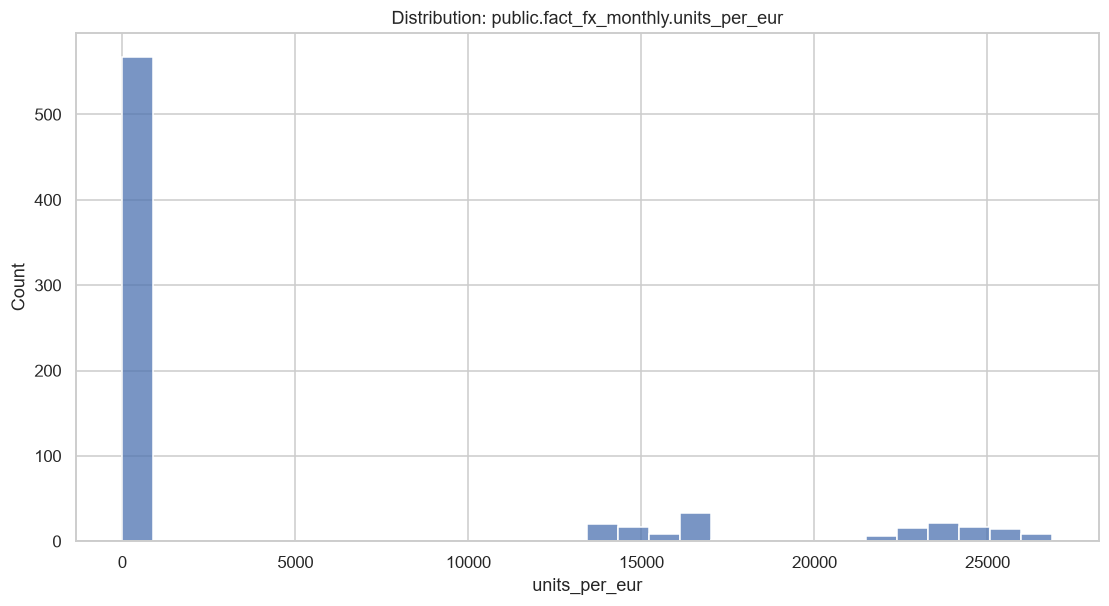

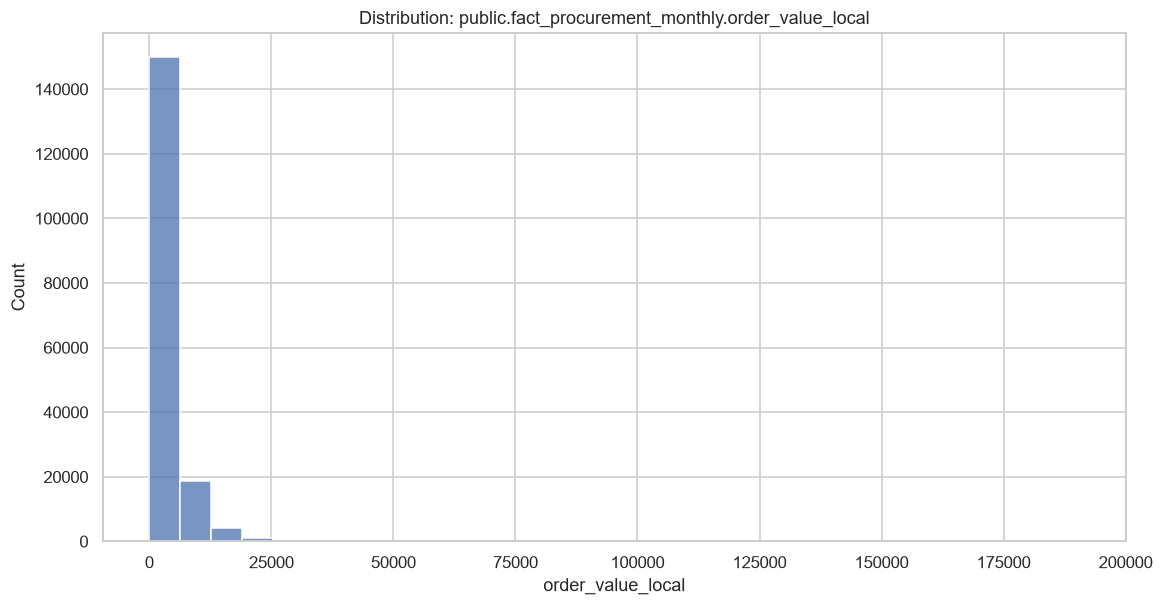

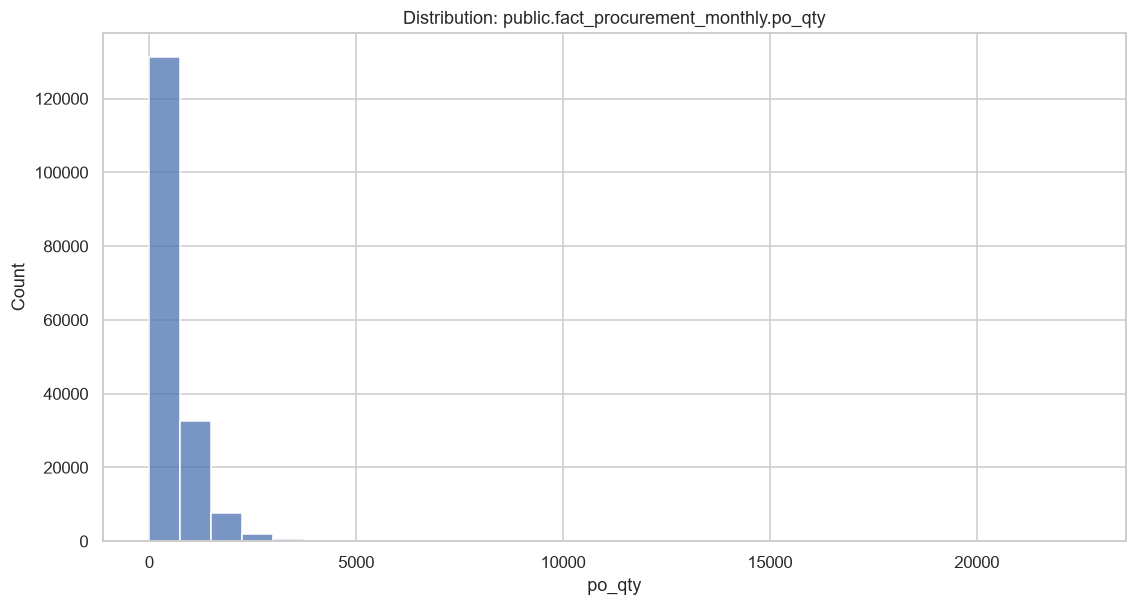

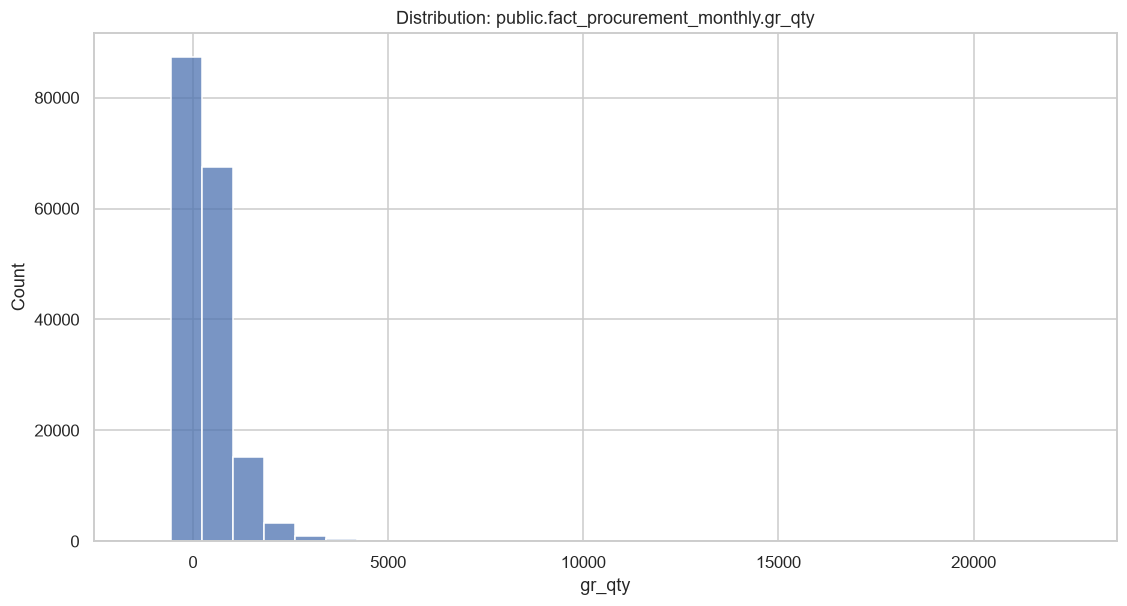

In [13]:
# 11. Distribution plots for live numeric data
plot_candidates = numeric_summary_df[numeric_summary_df['count'] > 0].head(12).to_dict('records') if not numeric_summary_df.empty else []
for item in plot_candidates:
    df = fetch_table(item['schema_name'], item['table_name'])
    series = pd.to_numeric(df[item['column_name']], errors='coerce').dropna()
    if series.empty:
        continue
    plt.figure()
    sns.histplot(series, bins=30, kde=False)
    plt.title(f"Distribution: {item['schema_name']}.{item['table_name']}.{item['column_name']}")
    plt.xlabel(item['column_name'])
    plt.ylabel('Count')
    plt.show()


## 6. Relationship and data-quality-register review

The database constraints are checked independently from the issue register. The issue register is evidence of recorded source-quality conditions; it is not treated as a complete scanner output. Where the procurement source deliberately retains a reported vendor value that is not constrained by a foreign key, that limitation is described rather than silently corrected.

In [14]:
# 12. Review the data-quality issue register when it exists
issue_candidates = inventory_df[inventory_df['object_name'].eq('data_quality_issue_register')]
if issue_candidates.empty:
    issue_register_df = pd.DataFrame()
    print('data_quality_issue_register was not discovered.')
else:
    issue_row = issue_candidates.iloc[0]
    issue_register_df = fetch_table(issue_row['schema_name'], issue_row['object_name'])
    print('Issue-register rows:', len(issue_register_df))
    if 'issue_code' in issue_register_df:
        display(issue_register_df['issue_code'].value_counts(dropna=False).rename_axis('issue_code').reset_index(name='count'))
    display(issue_register_df.head(20))


Issue-register rows: 2054


,issue_code,count
0,DQ11,204
1,DQ05,199
2,DQ07,198
3,DQ12,197
4,DQ01,193
5,DQ06,188
6,DQ04,186
7,DQ09,180
8,DQ03,177
9,DQ02,175


,issue_id,issue_code,table_name,record_id,business_key,description,recommended_handling
0,ISS000001,DQ12,fact_procurement_monthly.csv,POA0000211,VM00014|2023-12-01,Delayed GR,PO in month but receipt delayed or unmatched
1,ISS000002,DQ08,fact_procurement_monthly.csv,POA10000222,VM00014|2024-11-01,Duplicate business key,Repeated aggregate row; avoid double counting
2,ISS000003,DQ07,fact_procurement_monthly.csv,POA0000247,VM00021|2020-07-01,Invalid vendor key,FK mismatch requires master-data resolution
3,ISS000004,DQ05,fact_procurement_monthly.csv,POA0000300,VM00021|2025-06-01,Price spike,Extreme unit-price outlier
4,ISS000005,DQ04,fact_procurement_monthly.csv,POA0000303,VM00021|2025-10-01,Negative goods receipt,Return or reversal; do not discard without event context
5,ISS000006,DQ01,fact_procurement_monthly.csv,POA0000311,VM00021|2026-08-01,Missing order value,"NULL numeric; retained as missing, not zero"
6,ISS000007,DQ12,fact_procurement_monthly.csv,POA0000573,VM00042|2021-08-01,Delayed GR,PO in month but receipt delayed or unmatched
7,ISS000008,DQ09,fact_procurement_monthly.csv,POA0000591,VM00042|2023-04-01,Incorrect quantity unit,Unit conversion needed
8,ISS000009,DQ07,fact_procurement_monthly.csv,POA0000715,VM00051|2023-04-01,Invalid vendor key,FK mismatch requires master-data resolution
9,ISS000010,DQ01,fact_procurement_monthly.csv,POA0000769,VM00052|2022-06-01,Missing order value,"NULL numeric; retained as missing, not zero"


In [15]:
# 13. Targeted consistency checks for the known procurement relationships
consistency_checks = []
proc = 'fact_procurement_monthly'
bridge = 'bridge_vendor_material'
proc_schema = inventory_df.loc[inventory_df['object_name'].eq(proc), 'schema_name'].iloc[0] if not inventory_df.loc[inventory_df['object_name'].eq(proc)].empty else 'public'
bridge_schema = inventory_df.loc[inventory_df['object_name'].eq(bridge), 'schema_name'].iloc[0] if not inventory_df.loc[inventory_df['object_name'].eq(bridge)].empty else 'public'
if not inventory_df.query("object_name == @proc").empty and not inventory_df.query("object_name == @bridge").empty:
    mismatch_sql = f'''SELECT COUNT(*) AS mismatch_count
        FROM {object_ref(proc_schema, proc)} p
        JOIN {object_ref(bridge_schema, bridge)} b ON p.vendor_material_id = b.vendor_material_id
        WHERE p.vendor_id <> b.vendor_id'''
    try:
        mismatch_count = int(pd.read_sql_query(mismatch_sql, engine).iloc[0, 0])
        consistency_checks.append({'check': 'reported vendor differs from canonical bridge vendor', 'count': mismatch_count,
                                   'interpretation': 'Source discrepancy count; not changed by this notebook.'})
    except Exception as exc:
        consistency_checks.append({'check': 'reported vendor differs from canonical bridge vendor', 'count': np.nan,
                                   'interpretation': f'Not run: {exc}'})
consistency_df = pd.DataFrame(consistency_checks)
display(consistency_df)


,check,count,interpretation
0,reported vendor differs from canonical bridge vendor,198,Source discrepancy count; not changed by this notebook.


## 7. Findings, limitations, and reproducibility

The tables above are the findings. The notebook does not infer a business meaning from a statistical pattern. A `pass` means the specific executed check found no violations at execution time; it does not certify the source system or future loads. A failed or inaccessible check is retained with its status and should not be interpreted as clean data.

Known limitations include the synthetic/demo nature of the source package, intentionally injected data-quality conditions, structural missing months that do not appear as rows, and any PostgreSQL objects that are inaccessible to the current user.

To reproduce the report, activate `.ecco`, select its kernel in VS Code, confirm `.env` points to `ecco_procurement`, and run all cells from top to bottom. Credentials are read from `.env` and are not displayed.

In [16]:
# 14. Compact run summary
summary = {
    'execution_utc': datetime.now(timezone.utc).isoformat(),
    'database': db_name,
    'schema_count': len(schemas),
    'analyzed_objects': int((inventory_df['analysis_status'] == 'analyzed').sum()),
    'failed_objects': int((inventory_df['analysis_status'] == 'failed').sum()),
    'foreign_key_checks': int(len(fk_quality_df)),
    'foreign_key_failures': int((fk_quality_df['status'] == 'fail').sum()) if not fk_quality_df.empty else 0,
}
display(pd.DataFrame([summary]))


,execution_utc,database,schema_count,analyzed_objects,failed_objects,foreign_key_checks,foreign_key_failures
0,2026-10-29T20:06:47.008778+00:00,ecco_procurement,1,12,0,13,0
